# Machine Learning Lab 5 : KNN
## Name : Ishan Manekar 
## Class : A_A3_45

1. count chart 
2. pie chart
3. histogram
4. box plot
5. heatmap 
6. scatter plot
7. pair plot
8. x,y split

In [53]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, GridSearchCV, cross_val_score, StratifiedKFold)

from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score,confusion_matrix,classification_report)

In [55]:
df = pd.read_csv("diabetes (6).csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [57]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [59]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
763    False
764    False
765    False
766    False
767    False
Length: 768, dtype: bool

In [61]:
df.info

<bound method DataFrame.info of      Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0              6      148             72             35        0  33.6   
1              1       85             66             29        0  26.6   
2              8      183             64              0        0  23.3   
3              1       89             66             23       94  28.1   
4              0      137             40             35      168  43.1   
..           ...      ...            ...            ...      ...   ...   
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72             23      112  26.2   
766            1      126             60              0        0  30.1   
767            1       93             70             31        0  30.4   

     DiabetesPedigreeFunction  Age  Outcome  
0                       0.627   5

In [63]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [65]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [67]:
df.shape

(768, 9)

In [69]:
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [71]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [73]:
df.duplicated().sum()

0

In [ ]:
print(df["Outcomes"].value)

In [79]:
zero_cols = ["Glucose", "BloodPressure","SkinThickness","Insulin", "BMI"]

zero_counts = (df[zero_cols] == 0).sum()

print("Zero Values: ")
print(zero_counts)
# the data i snot missing any values but has zero in place where the values should have been 

Zero Values: 
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [85]:
df_clean = df.copy()
df_clean[zero_cols] = df.clean[zero_cols].replace(0,np.nan)

print("Missing values after replacing invalid zeros: ")
print(df_clean.isnull().sum())

Missing values after replacing invalid zeros: 
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [87]:
for col in zero_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Missing values after median imutation: ")
print(df_clean.isnull().sum())

Missing values after median imutation: 
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [91]:
## algo

In [93]:
X = df_clean.drop("Outcome", axis =1)

y = df_clean["Outcome"]

print("X shape : ", X.shape)
print("y shape : ", y.shape)

X shape :  (768, 8)
y shape :  (768,)


In [200]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size =0.20, random_state =54, stratify = y)

print("Training samples: ", X_train.shape[0])
print("Testing samples : ",  X_test.shape[0])

Training samples:  614
Testing samples :  154


In [202]:
print("Training distribution: ")
print(y_train.value_counts(normalize =True))

#testing ka bhi same 

Training distribution: 
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64


In [204]:
scaler = StandardScaler()

X_train_scaled =scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [206]:
scaler.fit_transform(X_test)

array([[-0.04591672, -0.6776565 , -0.31837594, ...,  0.06582896,
        -0.90111499, -0.00861694],
       [-0.04591672, -0.96817054,  1.26068669, ...,  0.73801478,
        -0.25567902, -0.38776229],
       [-0.32876373,  0.96858975,  0.31324911, ..., -1.55290425,
        -0.71670471,  0.37052841],
       ...,
       [-1.17730475, -0.64537716,  1.26068669, ...,  1.98635988,
         1.52893658, -0.19818961],
       [-0.61161073, -0.90361186, -0.79209473, ..., -0.09878798,
        -0.94573038, -0.86169397],
       [-1.17730475, -0.61309782,  0.31324911, ...,  0.46365322,
        -0.74347395, -0.6721213 ]])

In [208]:
scaler.transform(X_test)

array([[-0.04591672, -0.6776565 , -0.31837594, ...,  0.06582896,
        -0.90111499, -0.00861694],
       [-0.04591672, -0.96817054,  1.26068669, ...,  0.73801478,
        -0.25567902, -0.38776229],
       [-0.32876373,  0.96858975,  0.31324911, ..., -1.55290425,
        -0.71670471,  0.37052841],
       ...,
       [-1.17730475, -0.64537716,  1.26068669, ...,  1.98635988,
         1.52893658, -0.19818961],
       [-0.61161073, -0.90361186, -0.79209473, ..., -0.09878798,
        -0.94573038, -0.86169397],
       [-1.17730475, -0.61309782,  0.31324911, ...,  0.46365322,
        -0.74347395, -0.6721213 ]])

In [210]:
comparison = pd.DataFrame({
    "Original Mean": X_train.mean(),
    "Original Std" : X_train.std(),
    "Scaled Mean" : X_train_scaled.mean(axis=0),
    "Scaled Std" : X_train_scaled.std(axis=0)
})

display(comparison)

,Original Mean,Original Std,Scaled Mean,Scaled Std
Pregnancies,3.765472,3.321841,4.050325e-17,1.0
Glucose,122.073290,30.286444,2.227679e-16,1.0
BloodPressure,72.475570,11.947761,2.111955e-16,1.0
SkinThickness,29.166124,8.747972,3.182398e-17,1.0
Insulin,138.138436,79.942590,-9.257886e-17,1.0
BMI,32.489088,6.766639,-1.226670e-15,1.0
DiabetesPedigreeFunction,0.477875,0.329819,1.446545e-16,1.0
Age,33.278502,12.044871,1.591199e-16,1.0


In [212]:
K = 9 

In [214]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [216]:
y_pred = knn.predict(X_test_scaled)

print("Predictions: ")

print(y_pred[:20])

Predictions: 
[0 0 0 0 0 0 0 1 0 0 1 1 0 0 1 0 1 0 0 0]


In [218]:
y_prob = knn.predict_proba(X_test_scaled)[:,1]
print(y_prob[:20])

[0.  0.  0.4 0.4 0.4 0.4 0.  0.6 0.2 0.4 0.8 0.8 0.  0.4 1.  0.  0.8 0.
 0.2 0.4]


In [220]:
accuracy = accuracy_score(y_test,y_pred)
print(f"Accuracy:  { accuracy: .4f}")

Accuracy:   0.7662


In [222]:
precision = precision_score(y_test,y_pred)
print(f"Precision:  { precision: .4f}")

Precision:   0.6957


In [224]:
recall = recall_score(y_test,y_pred)
print(f"Recall:  {recall: .4f}")

Recall:   0.5926


In [228]:
f1 = f1_score(y_test,y_pred)
print(f"f1:  { f1: .4f}")

f1:   0.6400


In [230]:
k_values = range(1,51)

train_accuracy =[]
test_accuracy = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors =k)
    model.fit(X_train_scaled,y_train)
    train_accuracy.append(model.score(X_train_scaled,y_train))
    test_accuracy.append(model.score(X_test_scaled, y_test))

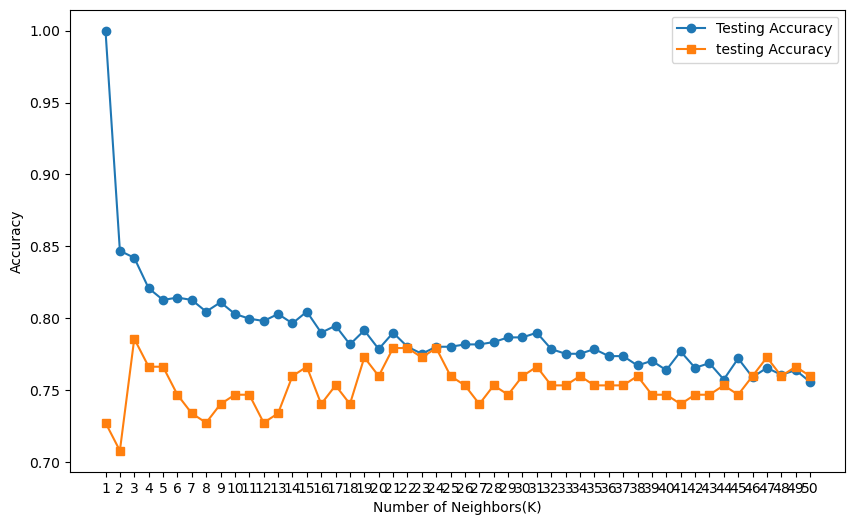

In [232]:
plt.figure(figsize = (10,6))

plt.plot(k_values,train_accuracy,marker = "o", label = "Testing Accuracy")

plt.plot(k_values,test_accuracy,marker="s", label = "testing Accuracy")

plt.xlabel("Number of Neighbors(K)")
plt.ylabel("Accuracy")
plt.xticks(k_values)
plt.legend()
plt.show()

In [234]:
best_k_accuracy = k_values[np.argmax(test_accuracy)]

best_accuracy =max(test_accuracy)

print("Best K : ", best_k_accuracy)
print("Best Test Accuracy: ", best_accuracy)

Best K :  3
Best Test Accuracy:  0.7857142857142857


In [240]:
cv = StratifiedKFold(n_splits = 5 , shuffle=True, random_state =54)

cv_scores =[]

for k in range (1,51):
    model = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(model, X_train_scaled, y_train,cv=cv, scoring="accuracy")
    cv_scores.append(scores.mean())

In [246]:
best_k_cv = np.argmax(cv_scores) + 1

print("Best K based on Cross Validation: ", best_k_cv)
print("Best CV Accuracy: ", max(cv_scores))

Best K based on Cross Validation:  11
Best CV Accuracy:  0.7703585232573638


In [253]:
param_grid = {"n_neighbors" : list(range(3,51,2)), "weights": ["uniform","distance"], 
             "metric": ["euclidean","manhattan","minkowski"],
             "p":[1,2]}

In [255]:
grid_search = GridSearchCV(estimator = KNeighborsClassifier(),param_grid=param_grid,cv=5,scoring="accuracy",n_jobs=-1)

grid_search.fit(X_train_scaled,y_train)
print("Grid Search Completed")

Grid Search Completed


In [259]:
print("Best Parameters: ")

print(grid_search.best_params_)

Best Parameters: 
{'metric': 'manhattan', 'n_neighbors': 9, 'p': 1, 'weights': 'uniform'}


In [261]:
print("Best Cross- Validation Accuracy:", grid_search.best_score_)

Best Cross- Validation Accuracy: 0.7802212448353991


In [263]:
best_knn = grid_search.best_estimator_
print(best_knn)

KNeighborsClassifier(metric='manhattan', n_neighbors=9, p=1)
